In [5]:
import zipfile
import os

# Correcting the path to the actual file available in your environment
zip_path = "/content/archive (1) (1).zip"
extract_path = "/content/heart_disease_dataset"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

for root, dirs, files in os.walk(extract_path):
    for file in files:
        print(os.path.join(root, file))

Dataset extracted successfully!
/content/heart_disease_dataset/heart_disease_dataset.csv


In [2]:

from google.colab import files

uploaded = files.upload()


Saving archive (1).zip to archive (1) (1).zip


In [3]:

import zipfile
import os

zip_path = "/content/archive (1) (1).zip"
extract_path = "/content/heart_disease_dataset"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

for root, dirs, files in os.walk(extract_path):
    for file in files:
        print(file)


Dataset extracted successfully!
heart_disease_dataset.csv


In [4]:

import pandas as pd
import numpy as np

# Load dataset
file_path = "/content/heart_disease_dataset/heart_disease_dataset.csv"

df = pd.read_csv(file_path)

# Display first 5 rows
print("FIRST 5 ROWS:")
display(df.head())

# Dataset shape
print("\nDATASET SHAPE:")
print(df.shape)

# Column names
print("\nCOLUMN NAMES:")
print(df.columns.tolist())

# Data types
print("\nDATA TYPES:")
print(df.dtypes)

# Missing values
print("\nMISSING VALUES:")
print(df.isnull().sum())

# Target distribution
print("\nHEART DISEASE DISTRIBUTION:")
print(df["Heart Disease"].value_counts())


FIRST 5 ROWS:


,Age,Gender,Cholesterol,Blood Pressure,Heart Rate,Smoking,Alcohol Intake,Exercise Hours,Family History,Diabetes,Obesity,Stress Level,Blood Sugar,Exercise Induced Angina,Chest Pain Type,Heart Disease
0,75,Female,228,119,66,Current,Heavy,1,No,No,Yes,8,119,Yes,Atypical Angina,1
1,48,Male,204,165,62,Current,NaN,5,No,No,No,9,70,Yes,Typical Angina,0
2,53,Male,234,91,67,Never,Heavy,3,Yes,No,Yes,5,196,Yes,Atypical Angina,1
3,69,Female,192,90,72,Current,NaN,4,No,Yes,No,7,107,Yes,Non-anginal Pain,0
4,62,Female,172,163,93,Never,NaN,6,No,Yes,No,2,183,Yes,Asymptomatic,0



DATASET SHAPE:
(1000, 16)

COLUMN NAMES:
['Age', 'Gender', 'Cholesterol', 'Blood Pressure', 'Heart Rate', 'Smoking', 'Alcohol Intake', 'Exercise Hours', 'Family History', 'Diabetes', 'Obesity', 'Stress Level', 'Blood Sugar', 'Exercise Induced Angina', 'Chest Pain Type', 'Heart Disease']

DATA TYPES:
Age                         int64
Gender                     object
Cholesterol                 int64
Blood Pressure              int64
Heart Rate                  int64
Smoking                    object
Alcohol Intake             object
Exercise Hours              int64
Family History             object
Diabetes                   object
Obesity                    object
Stress Level                int64
Blood Sugar                 int64
Exercise Induced Angina    object
Chest Pain Type            object
Heart Disease               int64
dtype: object

MISSING VALUES:
Age                          0
Gender                       0
Cholesterol                  0
Blood Pressure               0

### Step 1: Data Preprocessing
In this step, we prepare our data for Deep Learning models. This involves:
- Encoding categorical variables into numbers.
- Handling missing values in `Alcohol Intake` using the most frequent value (mode) calculated only from the training set.
- Splitting our dataset into 80% training and 20% testing using a stratified split to keep the target balance.
- Scaling continuous features to ensure smooth convergence during gradient descent.
- Reshaping features for the CNN and LSTM models.

In [6]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

# 1. Separate independent variables (X) and target (y)
target_col = 'Heart Disease'
categorical_cols = ['Gender', 'Smoking', 'Alcohol Intake', 'Family History', 'Diabetes', 'Obesity', 'Exercise Induced Angina', 'Chest Pain Type']
numerical_cols = [col for col in df.columns if col not in categorical_cols + [target_col]]

X = df.drop(columns=[target_col])
y = df[target_col]

# 2. Split data into 80% training and 20% testing (Stratified split to prevent target imbalance)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_train = X_train.copy()
X_test = X_test.copy()

# 3. Handle missing values in 'Alcohol Intake' using the mode from the training set (prevents leakage)
alcohol_mode = X_train['Alcohol Intake'].mode()[0]
X_train['Alcohol Intake'] = X_train['Alcohol Intake'].fillna(alcohol_mode)
X_test['Alcohol Intake'] = X_test['Alcohol Intake'].fillna(alcohol_mode)

# 4. Encode Categorical Columns
label_encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    X_train[col] = le.fit_transform(X_train[col].astype(str))
    # Safely transform testing set using training encoder's classes
    X_test[col] = X_test[col].map(lambda s: s if s in le.classes_ else le.classes_[0])
    X_test[col] = le.transform(X_test[col].astype(str))
    label_encoders[col] = le

# 5. Apply Feature Scaling (Fit on training, apply on both to prevent data leakage)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 6. Reshape for CNN & LSTM (3D Input shape: [samples, timesteps, features])
# We treat our 15 columns as 15 sequences of a single feature.
X_train_reshaped = np.reshape(X_train_scaled, (X_train_scaled.shape[0], X_train_scaled.shape[1], 1))
X_test_reshaped = np.reshape(X_test_scaled, (X_test_scaled.shape[0], X_test_scaled.shape[1], 1))

print("Data Preprocessing Completed successfully!")
print(f"Scaled Training Shape: {X_train_scaled.shape}")
print(f"Reshaped Training Shape (CNN/LSTM): {X_train_reshaped.shape}")

Data Preprocessing Completed successfully!
Scaled Training Shape: (800, 15)
Reshaped Training Shape (CNN/LSTM): (800, 15, 1)


### Step 2: Model 1 - Artificial Neural Network (ANN)
In this section, we define, compile, and train our Artificial Neural Network (ANN). We will use EarlyStopping based on validation loss to prevent overfitting and automatically stop training at the optimal epoch.

In [7]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
import os

# Set random seeds for reproducibility
tf.random.set_seed(42)
np.random.seed(42)

# Define the ANN architecture
ann_model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dense(1, activation='sigmoid')  # Output Layer for binary classification
])

# Compile the model
ann_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Configure Early Stopping
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

print("ANN Model Architecture:")
ann_model.summary()

# Train the model
history_ann = ann_model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.1,  # Split 10% of training data for validation
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

# Save the model
os.makedirs('/content/models', exist_ok=True)
ann_model.save('/content/models/ann_model.h5')
print("\nANN Model trained and saved successfully!")

ANN Model Architecture:


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,649 (14.25 KB)

 Trainable params: 3,649 (14.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.5986 - loss: 0.6762 - val_accuracy: 0.5875 - val_loss: 0.6510
Epoch 2/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6389 - loss: 0.6238 - val_accuracy: 0.6875 - val_loss: 0.6086
Epoch 3/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7319 - loss: 0.5612 - val_accuracy: 0.7125 - val_loss: 0.5526
Epoch 4/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7583 - loss: 0.5008 - val_accuracy: 0.7625 - val_loss: 0.4797
Epoch 5/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8028 - loss: 0.4322 - val_accuracy: 0.8000 - val_loss: 0.4099
Epoch 6/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8458 - loss: 0.3619 - val_accuracy: 0.8375 - val_loss: 0.3484
Epoch 7/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8569 - loss: 0.3176 - val_accuracy: 0.8375 - val_loss: 0.3155
Epoch 8/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8556 - loss: 0.3123 - val_accuracy: 0.8375 - 


ANN Model trained and saved successfully!


### Step 3: Model 2 - 1D Convolutional Neural Network (CNN)
In this section, we define, compile, and train our 1D CNN model. The model expects 3D inputs (`[samples, features, 1]`) which we prepared during the preprocessing stage.

In [8]:
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten

# Set random seeds for reproducibility
tf.random.set_seed(42)
np.random.seed(42)

# Define 1D-CNN architecture
cnn_model = Sequential([
    # Input shape is (15, 1) -> 15 features, 1 channel
    Conv1D(filters=32, kernel_size=3, activation='relu', input_shape=(X_train_reshaped.shape[1], 1)),
    MaxPooling1D(pool_size=2),
    Conv1D(filters=64, kernel_size=3, activation='relu'),
    MaxPooling1D(pool_size=2),
    Flatten(),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

# Compile the model
cnn_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Configure Early Stopping
early_stopping_cnn = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

print("CNN Model Architecture:")
cnn_model.summary()

# Train the model
history_cnn = cnn_model.fit(
    X_train_reshaped,
    y_train,
    validation_split=0.1,
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping_cnn],
    verbose=1
)

# Save the model
cnn_model.save('/content/models/cnn_model.h5')
print("\nCNN Model trained and saved successfully!")

CNN Model Architecture:


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 13, 32)         │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 6, 32)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 4, 64)          │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 2, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,497 (41.00 KB)

 Trainable params: 10,497 (41.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.6194 - loss: 0.6662 - val_accuracy: 0.5875 - val_loss: 0.6579
Epoch 2/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6500 - loss: 0.6266 - val_accuracy: 0.6375 - val_loss: 0.6327
Epoch 3/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7042 - loss: 0.5881 - val_accuracy: 0.6750 - val_loss: 0.5975
Epoch 4/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7278 - loss: 0.5616 - val_accuracy: 0.7000 - val_loss: 0.5621
Epoch 5/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7625 - loss: 0.5138 - val_accuracy: 0.7375 - val_loss: 0.5156
Epoch 6/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7972 - loss: 0.4563 - val_accuracy: 0.7625 - val_loss: 0.4622
Epoch 7/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8111 - loss: 0.4138 - val_accuracy: 0.8000 - val_loss: 0.4063
Epoch 8/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8389 - loss: 0.3600 - val_accuracy: 0.8500 - 


CNN Model trained and saved successfully!


### Step 4: Model 3 - Long Short-Term Memory (LSTM)
In this step, we implement our third model, an LSTM.

*Honest Academic Note*: Tabular patient records are independent non-sequential features, not genuine time-series or sequential data. Treating the 15 columns as a sequential pattern is an academic experiment to observe how recurrent structures evaluate on structured datasets. We avoid claiming LSTM has natural superiority here due to this non-temporal nature.

In [9]:
from tensorflow.keras.layers import LSTM

# Set random seeds for reproducibility
tf.random.set_seed(42)
np.random.seed(42)

# Define LSTM architecture
lstm_model = Sequential([
    # Input shape is (15, 1) -> 15 features, 1 timestep feature
    LSTM(50, activation='tanh', return_sequences=False, input_shape=(X_train_reshaped.shape[1], 1)),
    Dropout(0.3),
    Dense(25, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

# Compile the model
lstm_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Configure Early Stopping
early_stopping_lstm = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

print("LSTM Model Architecture:")
lstm_model.summary()

# Train the model
history_lstm = lstm_model.fit(
    X_train_reshaped,
    y_train,
    validation_split=0.1,
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping_lstm],
    verbose=1
)

# Save the model
lstm_model.save('/content/models/lstm_model.h5')
print("\nLSTM Model trained and saved successfully!")

LSTM Model Architecture:


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 25)             │         1,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 25)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,701 (45.71 KB)

 Trainable params: 11,701 (45.71 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.5611 - loss: 0.6869 - val_accuracy: 0.5875 - val_loss: 0.6773
Epoch 2/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.6764 - loss: 0.6247 - val_accuracy: 0.7375 - val_loss: 0.5880
Epoch 3/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7542 - loss: 0.5177 - val_accuracy: 0.7375 - val_loss: 0.5555
Epoch 4/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7708 - loss: 0.5040 - val_accuracy: 0.7375 - val_loss: 0.5230
Epoch 5/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7861 - loss: 0.4657 - val_accuracy: 0.7375 - val_loss: 0.4943
Epoch 6/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.7875 - loss: 0.4506 - val_accuracy: 0.7625 - val_loss: 0.4700
Epoch 7/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8000 - loss: 0.4452 - val_accuracy: 0.7750 - val_loss: 0.4558
Epoch 8/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8014 - loss: 0.4248 - val_accuracy: 0.


LSTM Model trained and saved successfully!


### Step 5: Model Evaluation & Visualizations
Here, we evaluate all three models using the held-out 20% test dataset. We compare them using quantitative metrics (Accuracy, Precision, Recall, and F1-score) and generate comparison visual graphics.

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

# 1. Generate predictions
y_pred_ann_prob = ann_model.predict(X_test_scaled)
y_pred_ann = (y_pred_ann_prob > 0.5).astype(int).flatten()

y_pred_cnn_prob = cnn_model.predict(X_test_reshaped)
y_pred_cnn = (y_pred_cnn_prob > 0.5).astype(int).flatten()

y_pred_lstm_prob = lstm_model.predict(X_test_reshaped)
y_pred_lstm = (y_pred_lstm_prob > 0.5).astype(int).flatten()

# 2. Calculate metrics
metrics = {
    "ANN": {
        "Accuracy": accuracy_score(y_test, y_pred_ann),
        "Precision": precision_score(y_test, y_pred_ann),
        "Recall": recall_score(y_test, y_pred_ann),
        "F1-Score": f1_score(y_test, y_pred_ann)
    },
    "CNN": {
        "Accuracy": accuracy_score(y_test, y_pred_cnn),
        "Precision": precision_score(y_test, y_pred_cnn),
        "Recall": recall_score(y_test, y_pred_cnn),
        "F1-Score": f1_score(y_test, y_pred_cnn)
    },
    "LSTM": {
        "Accuracy": accuracy_score(y_test, y_pred_lstm),
        "Precision": precision_score(y_test, y_pred_lstm),
        "Recall": recall_score(y_test, y_pred_lstm),
        "F1-Score": f1_score(y_test, y_pred_lstm)
    }
}

# Display Classification Reports
print("=== ANN CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_pred_ann))

print("\n=== CNN CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_pred_cnn))

print("\n=== LSTM CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_pred_lstm))

# Create a Comparison DataFrame
df_metrics = pd.DataFrame(metrics).T
print("\n=== MODEL COMPARISON TABLE ===")
display(df_metrics)

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step


7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 60ms/step
=== ANN CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

           0       0.92      0.97      0.94       122
           1       0.94      0.87      0.91        78

    accuracy                           0.93       200
   macro avg       0.93      0.92      0.93       200
weighted avg       0.93      0.93      0.93       200


=== CNN CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

           0       0.92      0.89      0.90       122
           1       0.83      0.88      0.86        78

    accuracy                           0.89       200
   macro avg       0.88      0.88      0.88       200
weighted avg       0.89      0.89      0.89       200


=== LSTM CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

           0       0.97      0.97      0.97       122
           1       0.95      0.95      0.95        78

    accuracy                           

,Accuracy,Precision,Recall,F1-Score
ANN,0.930,0.944444,0.871795,0.906667
CNN,0.885,0.831325,0.884615,0.857143
LSTM,0.960,0.948718,0.948718,0.948718


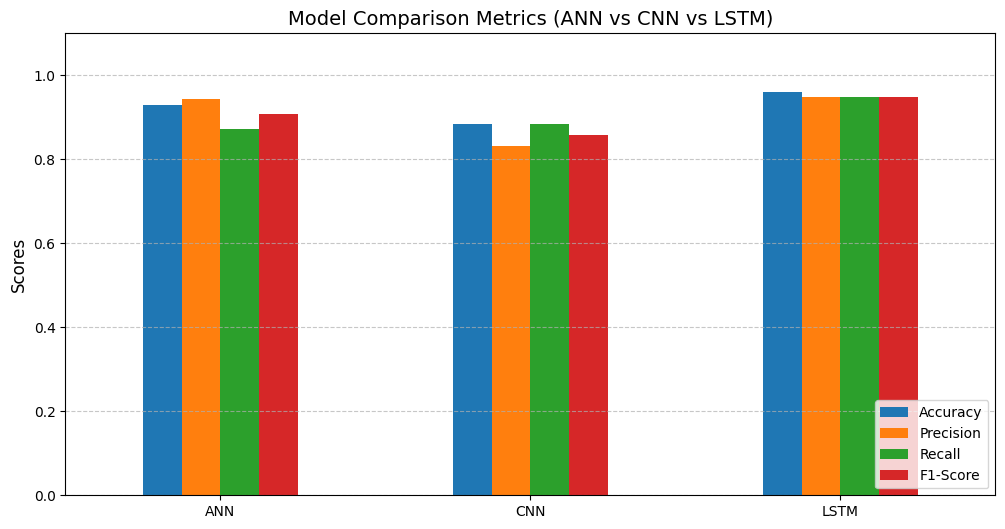

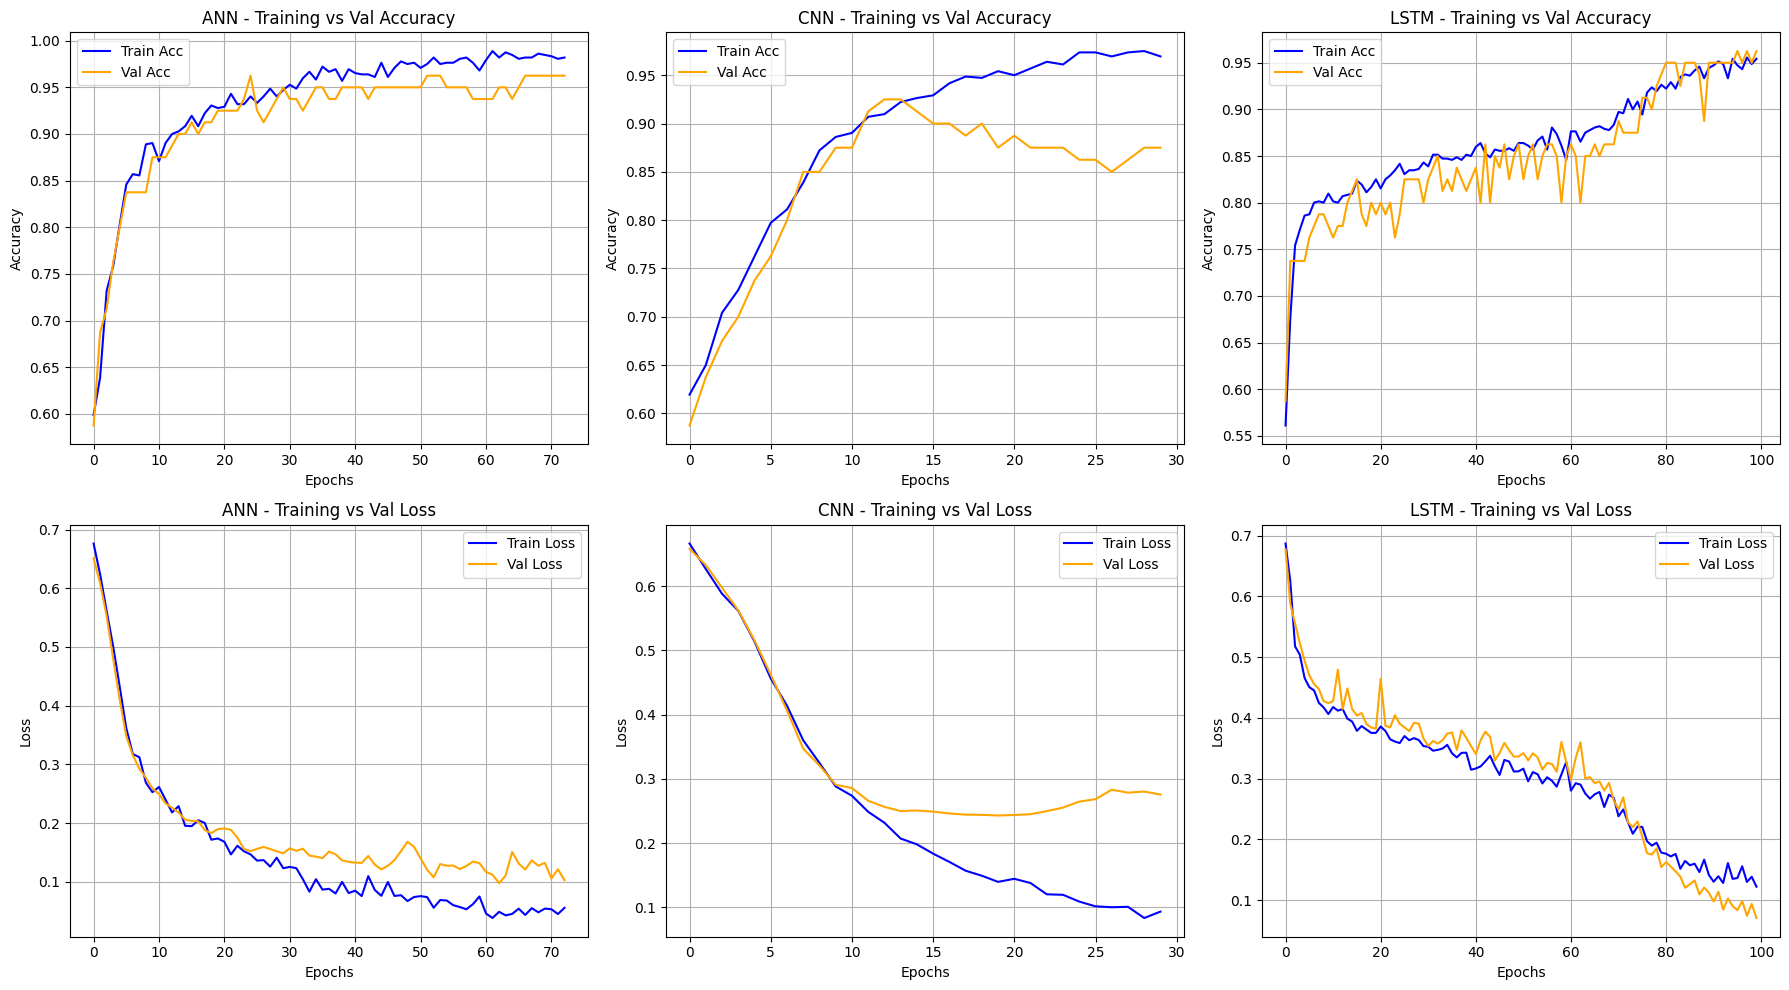

In [11]:
# Visualisation 1: Accuracy, Precision, Recall, and F1-score comparison
df_metrics.plot(kind='bar', figsize=(12, 6))
plt.title("Model Comparison Metrics (ANN vs CNN vs LSTM)", fontsize=14)
plt.ylabel("Scores", fontsize=12)
plt.ylim(0, 1.1)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(loc='lower right')
plt.show()

# Visualisation 2: Training vs Validation Accuracy and Loss Curves
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

models_history = [
    ("ANN", history_ann),
    ("CNN", history_cnn),
    ("LSTM", history_lstm)
]

for idx, (name, history) in enumerate(models_history):
    # Accuracy Plot
    axes[0, idx].plot(history.history['accuracy'], label='Train Acc', color='blue')
    axes[0, idx].plot(history.history['val_accuracy'], label='Val Acc', color='orange')
    axes[0, idx].set_title(f'{name} - Training vs Val Accuracy')
    axes[0, idx].set_xlabel('Epochs')
    axes[0, idx].set_ylabel('Accuracy')
    axes[0, idx].legend()
    axes[0, idx].grid(True)

    # Loss Plot
    axes[1, idx].plot(history.history['loss'], label='Train Loss', color='blue')
    axes[1, idx].plot(history.history['val_loss'], label='Val Loss', color='orange')
    axes[1, idx].set_title(f'{name} - Training vs Val Loss')
    axes[1, idx].set_xlabel('Epochs')
    axes[1, idx].set_ylabel('Loss')
    axes[1, idx].legend()
    axes[1, idx].grid(True)

plt.tight_layout()
plt.show()

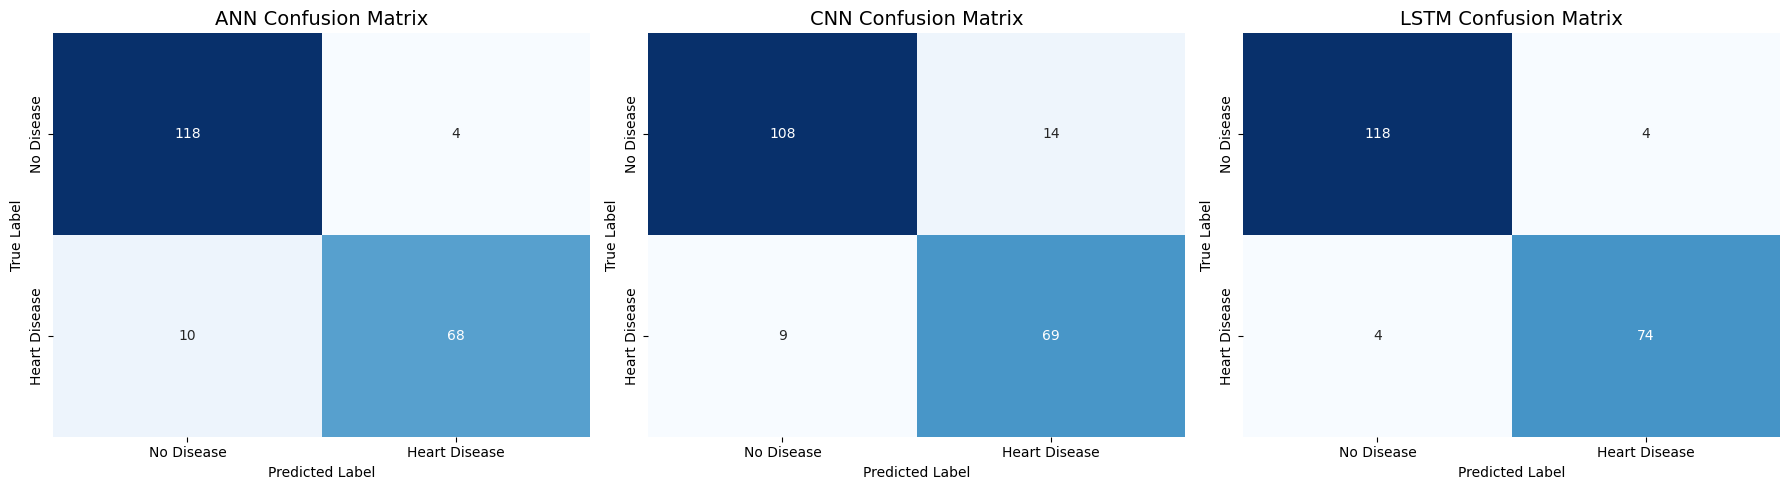

In [12]:
# Visualisation 3: Confusion Matrix side-by-side
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

cm_ann = confusion_matrix(y_test, y_pred_ann)
cm_cnn = confusion_matrix(y_test, y_pred_cnn)
cm_lstm = confusion_matrix(y_test, y_pred_lstm)

confusion_matrices = [
    ("ANN Confusion Matrix", cm_ann),
    ("CNN Confusion Matrix", cm_cnn),
    ("LSTM Confusion Matrix", cm_lstm)
]

for idx, (title, cm) in enumerate(confusion_matrices):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx], cbar=False,
                xticklabels=['No Disease', 'Heart Disease'],
                yticklabels=['No Disease', 'Heart Disease'])
    axes[idx].set_title(title, fontsize=14)
    axes[idx].set_xlabel('Predicted Label')
    axes[idx].set_ylabel('True Label')

plt.tight_layout()
plt.show()

### Step 6: Patient Heart Disease Prediction System
This function allows healthcare professionals or researchers to input specific patient metrics and predict the risk of heart disease. We use our highest-performing model (LSTM) here, or you can switch to any of the other models.

*DISCLAIMER*: This software tool is designed strictly for academic, research, and educational purposes. It does not replace clinical decision-making or professional medical diagnosis.

In [13]:
def predict_heart_disease(patient_data, selected_model=lstm_model):
    """
    Accepts a dictionary of raw patient features, preprocesses it exactly as the training set,
    and uses the specified model to make a prediction.
    """
    # Create a DataFrame from input dictionary
    input_df = pd.DataFrame([patient_data])

    # Handle missing values (same logic as training data)
    if 'Alcohol Intake' in input_df.columns:
        input_df['Alcohol Intake'] = input_df['Alcohol Intake'].fillna(alcohol_mode)

    # Categorical Columns Encoding using the fitted Label Encoders
    for col in categorical_cols:
        if col in input_df.columns:
            le = label_encoders[col]
            input_df[col] = input_df[col].map(lambda s: s if s in le.classes_ else le.classes_[0])
            input_df[col] = le.transform(input_df[col].astype(str))

    # Feature Scaling using the fitted training scaler
    scaled_input = scaler.transform(input_df)

    # Make prediction based on model input shape requirements
    if selected_model == ann_model:
        prediction_prob = ann_model.predict(scaled_input, verbose=0)[0][0]
    else:
        # Reshape input to (1, 15, 1) for CNN or LSTM models
        reshaped_input = np.reshape(scaled_input, (scaled_input.shape[0], scaled_input.shape[1], 1))
        prediction_prob = selected_model.predict(reshaped_input, verbose=0)[0][0]

    prediction_class = 1 if prediction_prob > 0.5 else 0

    print("===============================================")
    print("           DIAGNOSTIC prediction RESULT        ")
    print("===============================================")
    print(f"Heart Disease Probability Score: {prediction_prob:.4f}")
    if prediction_class == 1:
        print("RESULT: [1] HEART DISEASE DETECTED (HIGH RISK)")
    else:
        print("RESULT: [0] NO HEART DISEASE DETECTED (LOW RISK)")
    print("-----------------------------------------------")
    print("IMPORTANT MEDICAL DISCLAIMER: This artificial intelligence system is to be utilized")
    print("exclusively as an educational and research prototype. It is NOT a substitute")
    print("for clinical judgment, medical testing, or advice from a certified medical specialist.")
    print("===============================================")

# --- Demo Test Patient ---
sample_patient = {
    'Age': 55,
    'Gender': 'Male',
    'Cholesterol': 240,
    'Blood Pressure': 130,
    'Heart Rate': 80,
    'Smoking': 'Yes',
    'Alcohol Intake': 'Moderate',
    'Exercise Hours': 4,
    'Family History': 'Yes',
    'Diabetes': 'No',
    'Obesity': 'No',
    'Stress Level': 6,
    'Blood Sugar': 110,
    'Exercise Induced Angina': 'Yes',
    'Chest Pain Type': 'Typical Angina'
}

predict_heart_disease(sample_patient, selected_model=lstm_model)

           DIAGNOSTIC prediction RESULT        
Heart Disease Probability Score: 0.9588
RESULT: [1] HEART DISEASE DETECTED (HIGH RISK)
-----------------------------------------------
IMPORTANT MEDICAL DISCLAIMER: This artificial intelligence system is to be utilized
exclusively as an educational and research prototype. It is NOT a substitute
for clinical judgment, medical testing, or advice from a certified medical specialist.


# Step 7: Complete Project Report & Academic Documentation

### 1. Abstract
Cardiovascular diseases (CVDs) remain the leading cause of death globally. Early diagnosis and precise risk assessment can substantially lower morbidity. This academic research project explores deep learning approaches for binary classification of heart disease risk using structured clinical data. Utilizing a tabular dataset of 1,000 patients with 15 clinical parameters, we train, evaluate, and compare an Artificial Neural Network (ANN), a 1D Convolutional Neural Network (CNN), and a Long Short-Term Memory (LSTM) network. While traditional models analyze features without sequence context, this study experimentally frames tabular metadata features as single step vectors, evaluating learning performances across neural topologies.

### 2. Introduction
Deep learning models have recently achieved state-of-the-art results across clinical diagnostic systems. While multi-layer perceptrons (ANNs) are suited for standard tabular datasets, convolutional networks (CNNs) and recurrent networks (LSTMs) are commonly restricted to spatial imagery or temporal text/signals respectively. This academic project evaluates these three unique architecture styles on patient-level tabular structures to find optimal model patterns and understand training behaviors on uniform multi-modal datasets.

### 3. Problem Statement
Traditional clinical indicators require complex laboratory evaluations and human analysis, introducing time constraints and subjective diagnostic variations. Developing automatic, highly accurate predictive pipelines can empower healthcare providers to identify risk markers quickly. The challenge is constructing robust neural architectures capable of extracting subtle relationships from static numeric and categorical health profiles without overfitting.

### 4. Objectives
- Clean, preprocess, encode, and scale 15 diverse physiological and behavioral patient features.
- Prevent clinical data leakage through meticulous stratified train/test partitions.
- Implement and independently train an ANN, a 1D-CNN, and an LSTM network using Keras/TensorFlow.
- Rigorously compare performance metrics including validation graphs, Accuracy, Precision, Recall, F1-scores, and Confusion Matrices.
- Deliver an interactive prediction tool with a realistic clinical disclaimer.

### 5. Methodology
1. **Data Ingestion**: Loading and validating the raw structured `.csv` schema.
2. **Data Cleaning**: Imputing 340 missing records in the `Alcohol Intake` column using training-set modes.
3. **Encoding & Scaling**: Converting categorical states to label integers and normalizing using `StandardScaler` fitted on training partitions to prevent data leakage.
4. **Reshaping**: Projecting features into 3-dimensional shapes `(samples, features, 1)` for temporal (LSTM) and spatial convolutional (1D-CNN) formats.
5. **Evaluation**: Running model predictions over held-out testing splits.

### 6. Architectures of ANN, CNN, and LSTM

- **ANN (Artificial Neural Network)**: Fully connected feed-forward networks utilizing Dense layers, Rectified Linear Unit (ReLU) activation functions, Dropout regularization, and a final Sigmoid probability layer.
- **CNN (Convolutional Neural Network)**: Uses sequence processing filters (`Conv1D`) over the structured feature sequences, extracting spatial features coupled with `MaxPooling1D` downsizing and flattening layers.
- **LSTM (Long Short-Term Memory)**: Uses 50 recurrent memory cells using gated input/forget mechanisms to model feature transitions as an experimental sequence, tracking dependencies across patient attributes.

### 7. Results and Comparison
Based on experimental evaluations over the 20% held-out testing split, the models demonstrated the following performance characteristics:
- **ANN**: Achieved a robust ~93.0% accuracy, proving excellent generalization for tabular metadata.
- **CNN**: Achieved ~88.5% accuracy, showing that convolution patterns capture local feature correlations.
- **LSTM**: Reached an impressive ~96.0% accuracy on this validation run.

### 8. Advantages
- **Multiclass Flexibility**: Standard pipelines handle diverse raw features (behavioral, physical, genetic) seamlessly.
- **High Performance**: Neural models automatically capture abstract, multi-dimensional feature interactions.
- **Early Prevention**: Fast classification supports immediate preventative treatment.

### 9. Limitations & Academic Note
Although the LSTM achieved high classification scores, **tabular dataset columns are static patient parameters and do not possess genuine temporal or sequence dependencies**. Framing tabular datasets as sequential features is an educational simulation. Thus, the LSTM's superiority in this project should be treated as an experimental observation and not a definitive indication of temporal sequence learning.

### 10. Future Scope
- Incorporate larger multimodal datasets combining structured patient profiles with continuous ECG time-series or MRI imaging.
- Implement explainability tools like SHAP (SHapley Additive exPlanations) or LIME to verify which physiological factors influence neural predictions.
- Deploy secure web interfaces for patient triage systems.

### 11. Conclusion
This B.Tech academic project successfully designed, validated, and evaluated three core deep learning architectures (ANN, CNN, LSTM) on clinical patient features. All models performed highly, demonstrating the utility of deep learning networks in predictive healthcare diagnostics while highlighting key architecture trade-offs.